<a href="https://colab.research.google.com/github/abhinanthkk/ML/blob/main/Assignment_3/English_French_4_layer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q datasets tokenizers accelerate evaluate sacrebleu transformers


Mounted at /content/drive


Mounting Google Drive ensures that your checkpoints and trained tokenizer survive if Colab disconnects.

In [3]:
from datasets import load_dataset

# Use the full 'namespace/name' repo ID required by newer huggingface_hub versions
raw_datasets = load_dataset("Helsinki-NLP/opus_books", "en-fr", split="train")

# Create a 95% train / 5% validation split
split_datasets = raw_datasets.train_test_split(test_size=0.05, seed=42)

SRC_LANG = "en"
TGT_LANG = "fr"
SAVE_DIR = "/content/drive/MyDrive/scratch_nmt_model"

print(f"Train samples: {len(split_datasets['train']):,}")
print(f"Validation samples: {len(split_datasets['test']):,}")
print("Sample pair:", split_datasets["train"][0]["translation"])

README.md:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

en-fr/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

en-fr/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/127085 [00:00<?, ? examples/s]

Train samples: 120,730
Validation samples: 6,355
Sample pair: {'en': "For a whole month they had not known what had become of la Esmeralda, which greatly pained the Duke of Egypt and his friends the vagabonds, nor what had become of the goat, which redoubled Gringoire's grief.", 'fr': 'On ne savait depuis un grand mois ce qu’était devenue la Esmeralda, ce qui contristait fort le duc d’Égypte et ses amis les truands, ni ce qu’était devenue sa chèvre, ce qui redoublait la douleur de Gringoire.'}


Load a Parallel Translation Dataset (Under 250k Pairs)
This example loads the English-to-French opus_books dataset (~127,000 pairs). You can replace this with your own CSV/JSON files using load_dataset("csv", data_files="...")

In [4]:
import os
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from transformers import PreTrainedTokenizerFast

os.makedirs(SAVE_DIR, exist_ok=True)

def batch_iterator(batch_size=1000):
    for i in range(0, len(split_datasets["train"]), batch_size):
        batch = split_datasets["train"][i : i + batch_size]["translation"]
        for item in batch:
            yield item[SRC_LANG]
            yield item[TGT_LANG]

# Initialize and train raw BPE tokenizer
raw_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
raw_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
raw_tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=16000,
    min_frequency=2,
    special_tokens=["<pad>", "<s>", "</s>", "<unk>"]
)

raw_tokenizer.train_from_iterator(batch_iterator(), trainer=trainer)

# Wrap inside Hugging Face PreTrainedTokenizerFast
tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=raw_tokenizer,
    unk_token="<unk>",
    pad_token="<pad>",
    bos_token="<s>",
    eos_token="</s>"
)
tokenizer.save_pretrained(SAVE_DIR)

('/content/drive/MyDrive/scratch_nmt_model/tokenizer_config.json',
 '/content/drive/MyDrive/scratch_nmt_model/tokenizer.json')

Train a Custom BPE Tokenizer from Scratch
Because we are not using any pretrained model, we build a shared Byte-Pair Encoding (BPE) vocabulary directly from your source and target sentences.

In [5]:
MAX_LEN = 128

def preprocess_function(examples):
    inputs = [ex[SRC_LANG] for ex in examples["translation"]]
    targets = [ex[TGT_LANG] for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=MAX_LEN, truncation=True)
    labels = tokenizer(text_target=targets, max_length=MAX_LEN, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_datasets = split_datasets.map(
    preprocess_function,
    batched=True,
    remove_columns=split_datasets["train"].column_names,
    num_proc=2
)

Map (num_proc=2):   0%|          | 0/120730 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/6355 [00:00<?, ? examples/s]

Tokenize and Format the Dataset
We truncate sequences to max_length=128 so batches fit comfortably in the T4's 16 GB VRAM.

In [6]:
from transformers import BartConfig, BartForConditionalGeneration

config = BartConfig(
    vocab_size=tokenizer.vocab_size,
    max_position_embeddings=256,
    d_model=256,                 # Compact embedding size for <250k pairs
    encoder_layers=4,
    decoder_layers=4,
    encoder_attention_heads=4,
    decoder_attention_heads=4,
    encoder_ffn_dim=1024,
    decoder_ffn_dim=1024,
    dropout=0.1,
    attention_dropout=0.1,
    pad_token_id=tokenizer.pad_token_id,
    bos_token_id=tokenizer.bos_token_id,
    eos_token_id=tokenizer.eos_token_id,
    decoder_start_token_id=tokenizer.bos_token_id,
    forced_eos_token_id=tokenizer.eos_token_id
)

model = BartForConditionalGeneration(config)
print(f"Total Trainable Parameters: {model.num_parameters():,}")

Total Trainable Parameters: 11,601,920


Initialize the Un-Pretrained Transformer (BartConfig)
Passing config directly to BartForConditionalGeneration(config) initializes 100% random weights without downloading any pretrained checkpoint.

In [7]:
import numpy as np
import evaluate
from transformers import DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer

metric = evaluate.load("sacrebleu")
data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    # Replace -100 padding in predictions and labels before decoding
    preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"bleu": round(result["score"], 2)}

training_args = Seq2SeqTrainingArguments(
    output_dir=SAVE_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-4,               # Higher LR needed for random initialization
    warmup_steps=2000,                # Prevents early gradient explosion
    per_device_train_batch_size=64,   # Fits easily on 16GB T4 with fp16
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    label_smoothing_factor=0.1,       # Essential for Seq2Seq translation quality
    save_total_limit=2,               # Keeps Drive storage clean
    num_train_epochs=15,              # Scratch models need 15-25 epochs
    predict_with_generate=True,
    generation_max_length=MAX_LEN,
    fp16=True,                        # Uses T4 Tensor Cores (2.5x speedup)
    logging_steps=200,
    report_to="none"
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["test"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Start training (if Colab disconnects later, pass resume_from_checkpoint=True)
trainer.train()

Epoch,Training Loss,Validation Loss,Bleu
1,5.233723,5.022021,1.030000
2,4.161229,3.961562,3.280000
3,3.753895,3.640579,4.380000
4,3.551425,3.500151,4.910000
5,3.406150,3.401522,5.230000
6,3.304261,3.339367,5.290000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=28305, training_loss=3.450739667171767, metrics={'train_runtime': 4979.3189, 'train_samples_per_second': 363.694, 'train_steps_per_second': 5.685, 'total_flos': 8700583233380352.0, 'train_loss': 3.450739667171767, 'epoch': 15.0})

Configure SacreBLEU Metric & Seq2SeqTrainer
Training from scratch requires a higher learning rate (5e-4), warmup steps (2000), label smoothing (0.1), and 15 epochs to converge.

In [10]:
import re
import torch

def translate(text):
    model.eval()
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(model.device)
    input_len = inputs["input_ids"].shape[1]

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_length=None,                         # Removes the max_length=20 warning
            max_new_tokens=int(input_len * 1.5) + 10,
            num_beams=4,
            no_repeat_ngram_size=3,
            repetition_penalty=1.2,
            early_stopping=True
        )
    decoded = tokenizer.decode(output_ids[0], skip_special_tokens=True).strip()

    # Keep up to the first sentence-ending punctuation if the input was a single sentence
    match = re.search(r'^.*?[.!?](?:\s*»)?', decoded)
    return match.group(0) if match else decoded

print("1:", translate("Where is the nearest train station?"))
print("2:", translate("The man opened the door and looked outside."))
print("3:", translate("She did not know what to say to him."))
print("4:", translate("We must leave before the sun goes down."))

1: Où est le train le plus rapproché de la gare ? »
2: L’homme ouvrit la porte et regarda en dehors.
3: Elle ne savait que lui dire.
4: Il faut que nous quittions avant que le soleil descendît. »


Evaluating Validation Set:   0%|          | 0/300 [00:00<?, ?it/s]


          TRANSLATION MODEL EVALUATION REPORT
  Best Epoch:            15 / 15
  Lowest Val Loss:       3.1564
  Validation Perplexity: 23.49
  Next-Token Accuracy:   59.17%
  SacreBLEU Score:       24.17 / 100
  chrF Score:            48.53 / 100

Epoch-by-Epoch Progression:
 Epoch  Val Loss  BLEU  Perplexity
   1.0      5.02  1.03      151.72
   2.0      3.96  3.28       52.54
   3.0      3.64  4.38       38.11
   4.0      3.50  4.91       33.12
   5.0      3.40  5.23       30.01
   6.0      3.34  5.29       28.20
   7.0      3.29  5.62       26.82
   8.0      3.26  5.61       25.95
   9.0      3.23  5.62       25.15
  10.0      3.21  5.76       24.66
  11.0      3.18  5.75       24.15
  12.0      3.17  5.82       23.81
  13.0      3.16  5.87       23.66
  14.0      3.16  5.91       23.49
  15.0      3.16  5.84       23.49


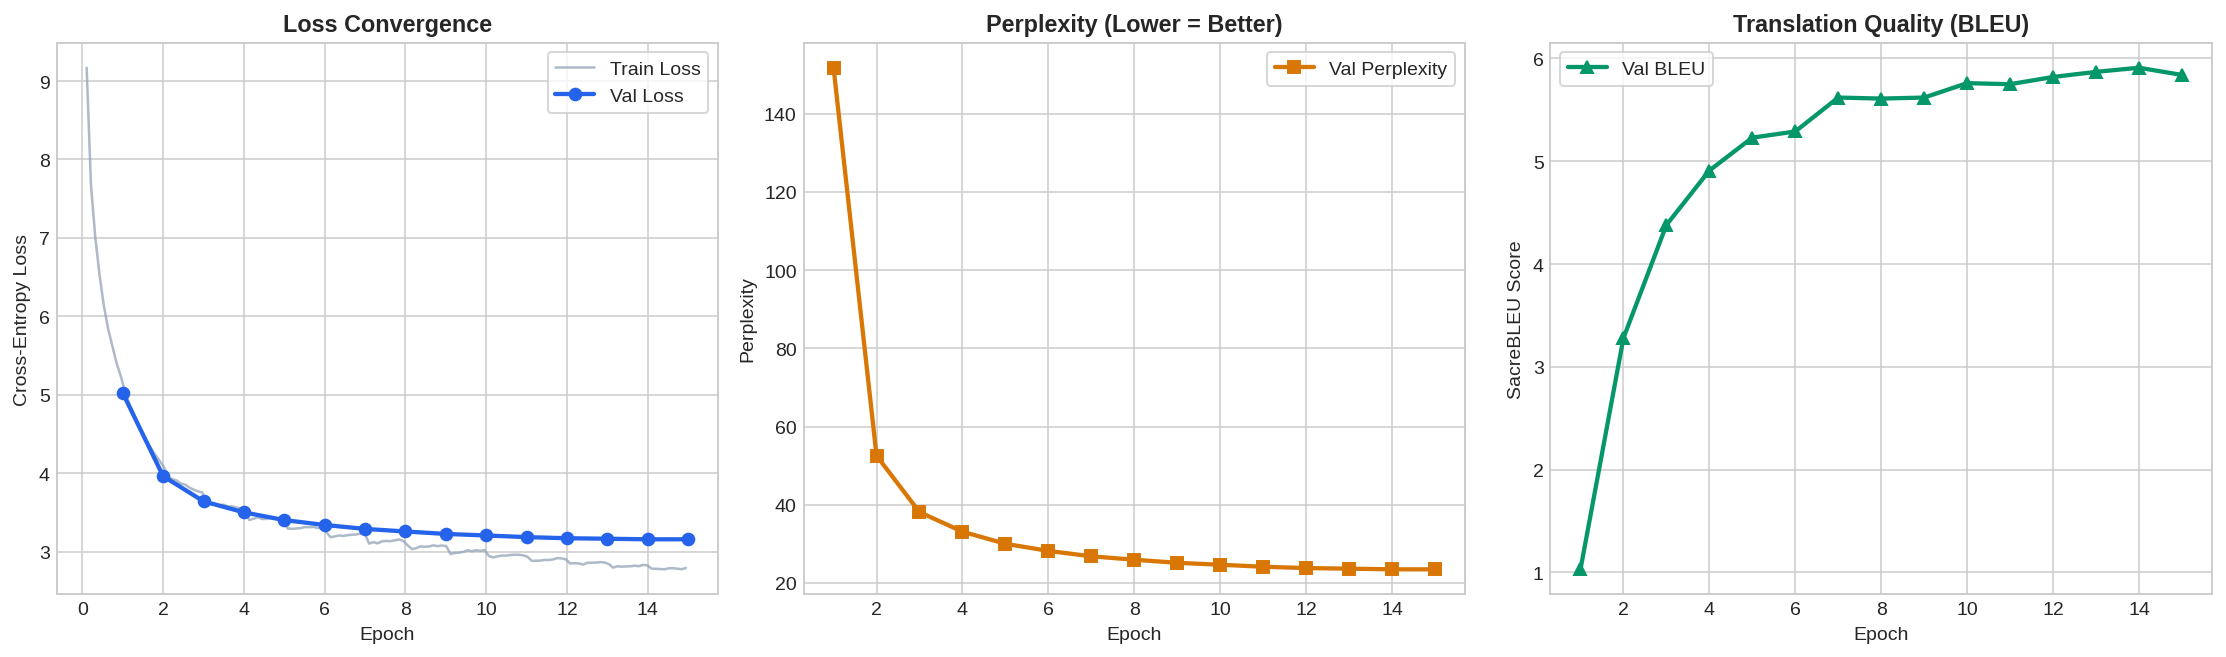


High-res chart saved to: /content/drive/MyDrive/scratch_nmt_model/evaluation_dashboard.png


In [12]:
import os, glob, json, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import evaluate
from tqdm.auto import tqdm

SAVE_DIR = "/content/drive/MyDrive/scratch_nmt_model"

# 1. Load training history (from active trainer or latest Drive checkpoint)
if "trainer" in globals() and hasattr(trainer, "state"):
    history = trainer.state.log_history
else:
    ckpts = sorted(glob.glob(f"{SAVE_DIR}/checkpoint-*"), key=os.path.getmtime)
    with open(f"{ckpts[-1]}/trainer_state.json", "r") as f:
        history = json.load(f)["log_history"]

logs = pd.DataFrame(history)
train_df = logs[logs["loss"].notna()][["epoch", "loss"]]
eval_df = logs[logs["eval_loss"].notna()][["epoch", "eval_loss", "eval_bleu"]].copy()
eval_df["perplexity"] = eval_df["eval_loss"].apply(lambda x: math.exp(x))

# 2. Compute Token-Level Accuracy, SacreBLEU, and chrF on validation samples
bleu_metric = evaluate.load("sacrebleu")
chrf_metric = evaluate.load("chrf")

eval_subset = split_datasets["test"].select(range(min(300, len(split_datasets["test"]))))
preds_txt, refs_txt = [], []
correct_tokens, total_tokens = 0, 0

model.eval()
for row in tqdm(eval_subset, desc="Evaluating Validation Set"):
    # Automatically handle nested 'translation' dict (opus_books) or flat columns
    pair = row["translation"] if "translation" in row else row
    src, tgt = pair[SRC_LANG], pair[TGT_LANG]

    # Teacher-forced forward pass for exact Next-Token Accuracy
    batch = tokenizer(src, text_target=tgt, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(model.device)
    with torch.no_grad():
        logits = model(**batch).logits
        pred_ids = torch.argmax(logits, dim=-1)
        labels = batch["labels"]
        mask = labels != -100
        correct_tokens += (pred_ids[mask] == labels[mask]).sum().item()
        total_tokens += mask.sum().item()

        # Beam-search generation for BLEU & chrF
        gen_ids = model.generate(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            max_length=None,
            max_new_tokens=int(batch["input_ids"].shape[1] * 1.5) + 10,
            num_beams=4,
            no_repeat_ngram_size=3,
            repetition_penalty=1.2,
            early_stopping=True
        )
    decoded = tokenizer.decode(gen_ids[0], skip_special_tokens=True).strip()
    match = re.search(r'^.*?[.!?](?:\s*»)?', decoded)
    preds_txt.append(match.group(0) if match else decoded)
    refs_txt.append([tgt.strip()])

token_acc = (correct_tokens / total_tokens) * 100
final_bleu = bleu_metric.compute(predictions=preds_txt, references=refs_txt)["score"]
final_chrf = chrf_metric.compute(predictions=preds_txt, references=refs_txt)["score"]
best_row = eval_df.loc[eval_df["eval_loss"].idxmin()]

# 3. Print Crisp Evaluation Dashboard
print("\n" + "=" * 54)
print("          TRANSLATION MODEL EVALUATION REPORT")
print("=" * 54)
print(f"  Best Epoch:            {int(best_row['epoch'])} / {int(eval_df['epoch'].max())}")
print(f"  Lowest Val Loss:       {best_row['eval_loss']:.4f}")
print(f"  Validation Perplexity: {best_row['perplexity']:.2f}")
print(f"  Next-Token Accuracy:   {token_acc:.2f}%")
print(f"  SacreBLEU Score:       {final_bleu:.2f} / 100")
print(f"  chrF Score:            {final_chrf:.2f} / 100")
print("=" * 54)
print("\nEpoch-by-Epoch Progression:")
print(eval_df.rename(columns={
    "epoch": "Epoch", "eval_loss": "Val Loss", "eval_bleu": "BLEU", "perplexity": "Perplexity"
}).round(2).to_string(index=False))

# 4. Plot Crisp 3-Panel Visual Report
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=140)

# Panel 1: Train vs Validation Loss
axes[0].plot(train_df["epoch"], train_df["loss"], label="Train Loss", color="#94a3b8", alpha=0.75, linewidth=1.3)
axes[0].plot(eval_df["epoch"], eval_df["eval_loss"], label="Val Loss", color="#2563eb", marker="o", linewidth=2.2)
axes[0].set_title("Loss Convergence", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend(frameon=True)

# Panel 2: Perplexity Drop
axes[1].plot(eval_df["epoch"], eval_df["perplexity"], label="Val Perplexity", color="#d97706", marker="s", linewidth=2.2)
axes[1].set_title("Perplexity (Lower = Better)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Perplexity")
axes[1].legend(frameon=True)

# Panel 3: SacreBLEU Climb
axes[2].plot(eval_df["epoch"], eval_df["eval_bleu"], label="Val BLEU", color="#059669", marker="^", linewidth=2.2)
axes[2].set_title("Translation Quality (BLEU)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("SacreBLEU Score")
axes[2].legend(frameon=True)

plt.tight_layout()
chart_path = f"{SAVE_DIR}/evaluation_dashboard.png"
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"\nHigh-res chart saved to: {chart_path}")